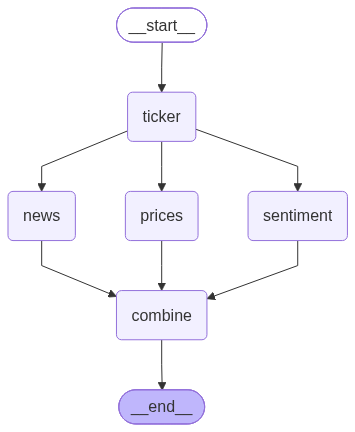

In [3]:
import operator, time
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    ticker: str
    results: Annotated[list[dict], operator.add]   # the reducer
    brief: str

def fetch_news(state: State):
    time.sleep(2)                                   # simulate a slow API call
    return {"results": [{"source": "news", "data": f"3 headlines about {state['ticker']}"}]}

def fetch_prices(state: State):
    time.sleep(2)
    return {"results": [{"source": "prices", "data": "up 2.1% today"}]}

def fetch_sentiment(state: State):
    time.sleep(2)
    return {"results": [{"source": "sentiment", "data": "mostly positive"}]}

def combine(state: State):
    lines = [f"{r['source']}: {r['data']}" for r in state["results"]]
    return {"brief": f"{state['ticker']} brief\n" + "\n".join(lines)}

def ask_tiker(state: State):
    return {"ticker": input("Enter a stock ticker: ")}

g = StateGraph(State)
g.add_node("news", fetch_news)
g.add_node("prices", fetch_prices)
g.add_node("sentiment", fetch_sentiment)
g.add_node("combine", combine)
g.add_node("ticker", ask_tiker)

# Fan-out: three edges leave START
g.add_edge(START, "ticker")
g.add_edge("ticker", "news")
g.add_edge("ticker", "prices")
g.add_edge("ticker", "sentiment")

# Fan-in: one edge with a LIST of sources waits for all of them
g.add_edge(["news", "prices", "sentiment"], "combine")
g.add_edge("combine", END)

g.compile()

In [6]:
app = g.compile()

start = time.time()
out = app.invoke({}) # type: ignore
print(out["brief"])
print(f"took {time.time() - start:.1f}s")    # ~2s, not ~6s

INFOSYS brief
news: 3 headlines about INFOSYS
prices: up 2.1% today
sentiment: mostly positive
took 5.8s
